# MeterTrace — Notebook 06: Model Evaluation

**Project:** MeterTrace: Electricity Theft Detection and Consumption Anomaly Analysis
**Phase:** 6 of 8

## Purpose
The final, fair comparison of all five models on the **held-out test customers**: 6,356 customers that no
model, scaler, threshold or design decision has ever seen.

| Model | Branch | Score | Trained in |
|---|---|---|---|
| Logistic Regression | Supervised | Theft probability | Notebook 04 |
| Random Forest | Supervised | Theft probability | Notebook 04 |
| LSTM classifier | Supervised | Theft probability | Notebook 05 |
| Isolation Forest | Unsupervised | Anomaly score | Notebook 04 |
| Dense autoencoder | Unsupervised | Reconstruction error | Notebook 05 |
| *Average consumption alone* | *Reference (no training)* | *`mean_kwh`* | — |

## The evaluation protocol (in this order)
1. Load the saved models, the saved validation scores and the existing splits. **Nothing is retrained or
   refitted.**
2. Choose **one threshold per model** with **one rule for all**: the threshold that **maximises F1 on
   validation customers**.
3. **Freeze** the thresholds by writing them to a file *before* any test score is computed.
4. Score the test customers **once** and compute every metric with the frozen thresholds.
5. Interpret the results. Nothing is changed after seeing them.

## 0. Setup

In [1]:
import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"   # hide TensorFlow's low-level C++ log messages (Python errors still show)

from pathlib import Path
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
import tensorflow as tf
import keras
from sklearn.metrics import (roc_auc_score, average_precision_score, roc_curve, precision_recall_curve,
                             precision_score, recall_score, f1_score, confusion_matrix)

I0000 00:00:1793257878.594115    2952 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1793257878.594928    2952 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


I0000 00:00:1793257879.980739    2952 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1793257879.981312    2952 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


In [2]:
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
tf.keras.utils.set_random_seed(RANDOM_STATE)

# ---- Paths (work from the notebooks/ folder or from the project root) ----
if Path.cwd().name == "notebooks":
    PROJECT_ROOT = Path.cwd().parent
else:
    PROJECT_ROOT = Path.cwd()

PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
MODEL_DIR = PROJECT_ROOT / "models"
FIGURE_DIR = PROJECT_ROOT / "outputs" / "figures"
RESULTS_DIR = PROJECT_ROOT / "outputs" / "results"

features_metadata = json.loads((PROCESSED_DIR / "features_metadata.json").read_text())
FEATURE_COLUMNS = features_metadata["feature_columns"]
LABEL_COLUMN = features_metadata["label_column"]

# Fixed model order and one fixed colour per model, used in every chart
MODEL_NAMES = ["Logistic Regression", "Random Forest", "LSTM classifier", "Isolation Forest", "Dense autoencoder"]
REFERENCE_NAME = "Average consumption alone"
ALL_NAMES = MODEL_NAMES + [REFERENCE_NAME]
SUPERVISED = ["Logistic Regression", "Random Forest", "LSTM classifier"]
UNSUPERVISED = ["Isolation Forest", "Dense autoencoder"]
MODEL_COLORS = {"Logistic Regression": "#2a78d6", "Random Forest": "#eb6834", "LSTM classifier": "#1baf7a",
                "Isolation Forest": "#eda100", "Dense autoencoder": "#e87ba4", REFERENCE_NAME: "#52514e"}
DEEP_COLOR = "#2a78d6"
CLASSICAL_COLOR = "#b4b3ad"
NEUTRAL_COLOR = "#52514e"
TOP_K_VALUES = [100, 500]

plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False
print("Models evaluated:", MODEL_NAMES, "+ reference:", REFERENCE_NAME)

Models evaluated: ['Logistic Regression', 'Random Forest', 'LSTM classifier', 'Isolation Forest', 'Dense autoencoder'] + reference: Average consumption alone


## 1. Load splits, saved validation scores and saved models

In [3]:
customers = pd.read_csv(PROCESSED_DIR / "customers.csv", index_col="CONS_NO")
print(customers["split"].value_counts().to_string())

# Validation scores saved by Notebooks 04 and 05 (same customer order)
scores_04 = pd.read_csv(RESULTS_DIR / "04_validation_scores.csv", index_col="CONS_NO")
scores_05 = pd.read_csv(RESULTS_DIR / "05_validation_scores.csv", index_col="CONS_NO")
validation_features = pd.read_parquet(PROCESSED_DIR / "features_validation.parquet")

print()
print("Notebook 04 and 05 validation scores in the same order:", bool((scores_04.index == scores_05.index).all()))
print("Validation features in the same order:                 ", bool((validation_features.index == scores_04.index).all()))
print("Validation customers match customers.csv:               ",
      set(scores_04.index) == set(customers.index[customers["split"] == "validation"]))

validation_scores = pd.DataFrame({
    LABEL_COLUMN: scores_04[LABEL_COLUMN],
    "Logistic Regression": scores_04["logistic_regression_probability"],
    "Random Forest": scores_04["random_forest_probability"],
    "LSTM classifier": scores_05["lstm_probability"],
    "Isolation Forest": scores_04["isolation_forest_anomaly_score"],
    "Dense autoencoder": scores_05["autoencoder_reconstruction_error"],
    REFERENCE_NAME: validation_features["mean_kwh"],          # no training, no fitting: just the feature
})
y_validation = validation_scores[LABEL_COLUMN].to_numpy()
print("Validation customers:", len(validation_scores), "| theft:", int(y_validation.sum()))

split
train                     29657
test                       6356
validation                 6354
excluded (no readings)        5

Notebook 04 and 05 validation scores in the same order: True
Validation features in the same order:                  True
Validation customers match customers.csv:                True
Validation customers: 6354 | theft: 540


In [4]:
logistic_regression = joblib.load(MODEL_DIR / "logistic_regression.joblib")
random_forest = joblib.load(MODEL_DIR / "random_forest.joblib")
isolation_forest = joblib.load(MODEL_DIR / "isolation_forest.joblib")
lstm_model = keras.models.load_model(MODEL_DIR / "lstm_classifier.keras")
autoencoder = keras.models.load_model(MODEL_DIR / "dense_autoencoder.keras")
print("Loaded 5 saved models. No model is trained or refitted in this notebook.")

Loaded 5 saved models. No model is trained or refitted in this notebook.


### Are these exactly the models from Notebooks 04 and 05?
We re-score the validation customers with the loaded models and compare the results with the saved
validation scores. If they match, the thresholds we choose belong to the same models we will test.

In [5]:
validation_weekly = np.load(PROCESSED_DIR / "weekly_validation.npz")
X_validation_features = validation_features[FEATURE_COLUMNS]
X_validation_weekly = validation_weekly["values"]
print("Validation weekly order matches:", bool((validation_weekly["customer_ids"] == validation_scores.index.to_numpy()).all()))

rescored_validation = {
    "Logistic Regression": logistic_regression.predict_proba(X_validation_features)[:, 1],
    "Random Forest": random_forest.predict_proba(X_validation_features)[:, 1],
    "LSTM classifier": lstm_model(X_validation_weekly[:, :, np.newaxis], training=False).numpy().ravel(),
    "Isolation Forest": -isolation_forest.score_samples(X_validation_features),
    "Dense autoencoder": np.mean((X_validation_weekly - autoencoder(X_validation_weekly, training=False).numpy()) ** 2, axis=1),
}
for model_name in MODEL_NAMES:
    print(f"{model_name:20s} reloaded model reproduces saved validation scores:",
          np.allclose(rescored_validation[model_name], validation_scores[model_name], atol=1e-5))

Validation weekly order matches: True


Logistic Regression  reloaded model reproduces saved validation scores: True
Random Forest        reloaded model reproduces saved validation scores: True
LSTM classifier      reloaded model reproduces saved validation scores: True
Isolation Forest     reloaded model reproduces saved validation scores: True
Dense autoencoder    reloaded model reproduces saved validation scores: True


## 2. Choose thresholds on validation customers (one rule for all models)
A model gives each customer a **score**. To turn scores into a yes/no decision ("flag for inspection") we
need a **threshold**: flag if `score ≥ threshold`.

**Rule (identical for all five models and the reference):** choose the threshold that gives the **highest
F1-score on validation customers**. F1 is the harmonic mean of precision and recall, so it rewards
thresholds that find theft cases *without* flagging too many normal customers.

`precision_recall_curve` lists every possible threshold with its precision and recall. We compute F1 for
each and keep the best. Test customers play **no** part in this.

In [6]:
threshold_rows = []
for model_name in ALL_NAMES:
    precision, recall, thresholds = precision_recall_curve(y_validation, validation_scores[model_name])
    precision = precision[:-1]          # the last point has no threshold
    recall = recall[:-1]
    f1_values = np.divide(2 * precision * recall, precision + recall,
                          out=np.zeros_like(precision), where=(precision + recall) > 0)
    best = int(np.argmax(f1_values))
    flagged = validation_scores[model_name].to_numpy() >= thresholds[best]
    threshold_rows.append({
        "Model": model_name,
        "Threshold": thresholds[best],
        "Validation precision": precision[best],
        "Validation recall": recall[best],
        "Validation F1": f1_values[best],
        "Validation customers flagged": int(flagged.sum()),
    })

validation_thresholds = pd.DataFrame(threshold_rows).set_index("Model")
validation_thresholds

,Threshold,Validation precision,Validation recall,Validation F1,Validation customers flagged
Model,,,,,
Logistic Regression,0.577957,0.219029,0.409259,0.285345,1009
Random Forest,0.250000,0.440204,0.320370,0.370847,393
LSTM classifier,0.565368,0.197550,0.477778,0.279523,1306
Isolation Forest,0.391531,0.110173,0.531481,0.182512,2605
Dense autoencoder,0.100883,0.171429,0.277778,0.212014,875
Average consumption alone,17.060921,0.219761,0.238889,0.228926,587


### Freeze the thresholds
The thresholds are written to disk **now**, before any test score exists. The test evaluation below reads
them back from this file, so they cannot be adjusted afterwards.

In [7]:
validation_thresholds.to_csv(RESULTS_DIR / "06_validation_thresholds.csv")
frozen_thresholds = pd.read_csv(RESULTS_DIR / "06_validation_thresholds.csv", index_col="Model")["Threshold"]
print("Frozen thresholds saved to outputs/results/06_validation_thresholds.csv")
print(frozen_thresholds.to_string())

Frozen thresholds saved to outputs/results/06_validation_thresholds.csv
Model
Logistic Regression           0.577957
Random Forest                 0.250000
LSTM classifier               0.565368
Isolation Forest              0.391531
Dense autoencoder             0.100883
Average consumption alone    17.060921


### The trade-off behind any threshold (validation customers, Random Forest)
A lower threshold catches more theft (higher **recall**) but also flags more normal customers (higher
**false-positive rate**, lower **precision**). The table shows this on **validation** customers for a few
"inspect the top X%" choices. It is an illustration, and the F1 rule above has already fixed the
threshold.

In [8]:
rf_validation_scores = validation_scores["Random Forest"].to_numpy()
tradeoff_rows = []
for share_flagged in [0.01, 0.05, 0.10, 0.20, 0.40]:
    cut = np.quantile(rf_validation_scores, 1 - share_flagged)
    flagged = rf_validation_scores >= cut
    true_negatives, false_positives, false_negatives, true_positives = confusion_matrix(y_validation, flagged).ravel()
    tradeoff_rows.append({
        "Customers flagged (%)": share_flagged * 100,
        "Precision": true_positives / max(true_positives + false_positives, 1),
        "Recall (theft caught)": true_positives / (true_positives + false_negatives),
        "False-positive rate (normal flagged)": false_positives / (false_positives + true_negatives),
    })
pd.DataFrame(tradeoff_rows).round(3)

,Customers flagged (%),Precision,Recall (theft caught),False-positive rate (normal flagged)
0,1.0,0.719,0.085,0.003
1,5.0,0.453,0.278,0.031
2,10.0,0.317,0.398,0.080
3,20.0,0.228,0.543,0.170
4,40.0,0.154,0.754,0.385


**What we see (validation only).**
- **The thresholds differ a lot between models**, because the scores mean different things:
  - probabilities: Logistic Regression 0.578, Random Forest 0.250, LSTM 0.565;
  - an anomaly score: Isolation Forest 0.392;
  - a reconstruction error: autoencoder 0.101;
  - kWh per day: average consumption 17.06.

  This is why every model needs its own threshold, even under one shared rule.
- **The F1 rule flags very different numbers of validation customers**, from 393 (Random Forest) to
  2,605 (Isolation Forest).
  - Random Forest's best F1 comes from a *cautious* threshold: precision 0.440, recall 0.320.
  - Isolation Forest's best F1 comes from flagging widely: precision 0.110, recall 0.531.
- **The trade-off table** shows the cost of catching more theft with Random Forest. Inspecting the top 5%
  catches 27.8% of theft cases with 45.3% precision. Inspecting the top 40% catches 75.4%, but then
  38.5% of normal customers are flagged and precision falls to 15.4%.

These thresholds are now **frozen** in `06_validation_thresholds.csv`.

## 3. Score the held-out test customers (once)
We load the test features and the test weekly sequences, check that they describe the **same customers in the
same order**, and run each saved model **once**.

In [9]:
test_features = pd.read_parquet(PROCESSED_DIR / "features_test.parquet")
test_weekly = np.load(PROCESSED_DIR / "weekly_test.npz")

X_test_features = test_features[FEATURE_COLUMNS]
X_test_weekly = test_weekly["values"]
y_test = test_features[LABEL_COLUMN].to_numpy()

print("Test customers:", len(test_features), "| theft:", int(y_test.sum()), f"({y_test.mean():.2%})")
print("Feature and sequence files in the same customer order:", bool((test_features.index.to_numpy() == test_weekly["customer_ids"]).all()))
print("Labels identical in both files:                        ", bool((test_weekly["labels"] == y_test).all()))
print("Same customers as the test split in customers.csv:     ", set(test_features.index) == set(customers.index[customers["split"] == "test"]))
print("No test customer in train or validation:               ",
      len(set(test_features.index) & set(customers.index[customers["split"].isin(["train", "validation"])])) == 0)

Test customers: 6356 | theft: 542 (8.53%)
Feature and sequence files in the same customer order: True
Labels identical in both files:                         True
Same customers as the test split in customers.csv:      True


No test customer in train or validation:                True


In [10]:
test_scores = pd.DataFrame({
    LABEL_COLUMN: y_test,
    "Logistic Regression": logistic_regression.predict_proba(X_test_features)[:, 1],
    "Random Forest": random_forest.predict_proba(X_test_features)[:, 1],
    "LSTM classifier": lstm_model(X_test_weekly[:, :, np.newaxis], training=False).numpy().ravel(),
    "Isolation Forest": -isolation_forest.score_samples(X_test_features),
    "Dense autoencoder": np.mean((X_test_weekly - autoencoder(X_test_weekly, training=False).numpy()) ** 2, axis=1),
    REFERENCE_NAME: X_test_features["mean_kwh"].to_numpy(),
}, index=test_features.index)

print("Score table:", test_scores.shape)
print("Missing scores:", int(test_scores.isna().sum().sum()), "| infinite scores:", int(np.isinf(test_scores[ALL_NAMES].to_numpy()).sum()))

Score table: (6356, 7)
Missing scores: 0 | infinite scores: 0


## 4. Test metrics with the frozen thresholds
For every model, on the **same 6,356 test customers**:

| Metric | Meaning |
|---|---|
| Precision | Of the customers flagged, the share labelled theft |
| Recall | Of the theft-labelled customers, the share flagged |
| F1 | Balance of precision and recall |
| False-positive rate | Of the normal customers, the share wrongly flagged |
| ROC-AUC / PR-AUC | Ranking quality over **all** thresholds (no threshold needed) |
| Precision@100 / @500 | Share of theft among the **100 / 500 highest-scored** test customers: an inspection budget |

For Precision@k, customers with exactly equal scores keep their saved row order (`kind="stable"`), so the
result is reproducible.

In [11]:
metric_rows = []
for model_name in ALL_NAMES:
    scores = test_scores[model_name].to_numpy()
    flagged = scores >= frozen_thresholds[model_name]
    true_negatives, false_positives, false_negatives, true_positives = confusion_matrix(y_test, flagged).ravel()
    ranking = np.argsort(-scores, kind="stable")
    row = {
        "Model": model_name,
        "Branch": "Supervised" if model_name in SUPERVISED else ("Unsupervised" if model_name in UNSUPERVISED else "Reference"),
        "Threshold (from validation)": frozen_thresholds[model_name],
        "Precision": precision_score(y_test, flagged, zero_division=0),
        "Recall": recall_score(y_test, flagged),
        "F1": f1_score(y_test, flagged),
        "False-positive rate": false_positives / (false_positives + true_negatives),
        "ROC-AUC": roc_auc_score(y_test, scores),
        "PR-AUC": average_precision_score(y_test, scores),
        "TP": true_positives, "FP": false_positives, "FN": false_negatives, "TN": true_negatives,
        "Flagged": int(flagged.sum()),
    }
    for k in TOP_K_VALUES:
        row[f"Precision@{k}"] = y_test[ranking[:k]].mean()
    metric_rows.append(row)

test_metrics = pd.DataFrame(metric_rows).set_index("Model")
test_metrics.to_csv(RESULTS_DIR / "06_test_metrics.csv")

display_columns = ["Branch", "Precision", "Recall", "F1", "False-positive rate", "ROC-AUC", "PR-AUC",
                   "Precision@100", "Precision@500", "Flagged"]
test_metrics[display_columns].round(4)

,Branch,Precision,Recall,F1,False-positive rate,ROC-AUC,PR-AUC,Precision@100,Precision@500,Flagged
Model,,,,,,,,,,
Logistic Regression,Supervised,0.2259,0.4059,0.2902,0.1297,0.7456,0.2539,0.51,0.292,974
Random Forest,Supervised,0.4245,0.3266,0.3691,0.0413,0.7702,0.3389,0.68,0.380,417
LSTM classifier,Supervised,0.2003,0.4852,0.2836,0.1806,0.7216,0.2189,0.36,0.262,1313
Isolation Forest,Unsupervised,0.1103,0.5498,0.1837,0.4135,0.6031,0.1549,0.40,0.168,2702
Dense autoencoder,Unsupervised,0.1721,0.2897,0.2160,0.1299,0.6540,0.1740,0.41,0.234,912
Average consumption alone,Reference,0.2358,0.2601,0.2474,0.0786,0.6695,0.2033,0.44,0.246,598


In [12]:
print("Confusion-matrix counts on the test set (threshold from validation):")
test_metrics[["TP", "FP", "FN", "TN", "Flagged"]]

Confusion-matrix counts on the test set (threshold from validation):


,TP,FP,FN,TN,Flagged
Model,,,,,
Logistic Regression,220,754,322,5060,974
Random Forest,177,240,365,5574,417
LSTM classifier,263,1050,279,4764,1313
Isolation Forest,298,2404,244,3410,2702
Dense autoencoder,157,755,385,5059,912
Average consumption alone,141,457,401,5357,598


### Tie check for Precision@k
If several customers have **exactly the same score** at the cut-off (rank 100 or 500), which of them count as
"top k" depends on the tie-break. Below, for each model, we count the customers tied at the cut-off and the
lowest and highest Precision@k that any tie-break could give.

In [13]:
tie_rows = []
for model_name in ALL_NAMES:
    scores = test_scores[model_name].to_numpy()
    ranking = np.argsort(-scores, kind="stable")
    for k in TOP_K_VALUES:
        cut_score = scores[ranking[k - 1]]
        above_cut = scores > cut_score
        at_cut = scores == cut_score
        places_left = k - int(above_cut.sum())
        theft_above = int(y_test[above_cut].sum())
        theft_at_cut = int(y_test[at_cut].sum())
        normal_at_cut = int(at_cut.sum()) - theft_at_cut
        tie_rows.append({
            "Model": model_name, "k": k,
            "Customers tied at the cut-off": int(at_cut.sum()),
            "Reported Precision@k": y_test[ranking[:k]].mean(),
            "Lowest possible": (theft_above + max(0, places_left - normal_at_cut)) / k,
            "Highest possible": (theft_above + min(places_left, theft_at_cut)) / k,
        })
pd.DataFrame(tie_rows).set_index(["Model", "k"]).round(3)

Customers tied at the cut-off  \
Model                     k                                    
Logistic Regression       100                              1   
                          500                              1   
Random Forest             100                              7   
                          500                             48   
LSTM classifier           100                              1   
                          500                              1   
Isolation Forest          100                              1   
                          500                              1   
Dense autoencoder         100                              1   
                          500                              1   
Average consumption alone 100                              1   
                          500                              1   

                               Reported Precision@k  Lowest possible  \
Model                     k                                            
Logistic Regression       100                 0.510            0.510   
                          500                 0.292            0.292   
Random Forest             100                 0.680            0.680   
                          500                 0.380            0.376   
LSTM classifier           100                 0.360            0.360   
                          500                 0.262            0.262   
Isolation Forest          100                 0.400            0.400   
                          500                 0.168            0.168   
Dense autoencoder         100                 0.410            0.410   
                          500                 0.234            0.234   
Average consumption alone 100                 0.440            0.440   
                          500                 0.246            0.246   

                               Highest possible  
Model                     k                      
Logistic Regression       100             0.510  
                          500             0.292  
Random Forest             100             0.690  
                          500             0.386  
LSTM classifier           100             0.360  
                          500             0.262  
Isolation Forest          100             0.400  
                          500             0.168  
Dense autoencoder         100             0.410  
                          500             0.234  
Average consumption alone 100             0.440  
                          500             0.246

In [14]:
print(f"Test theft share (= PR-AUC and Precision@k of a random ranking): {y_test.mean():.4f}")
print(f"Accuracy of predicting 'normal' for everyone on test:          {1 - y_test.mean():.4f}")

Test theft share (= PR-AUC and Precision@k of a random ranking): 0.0853
Accuracy of predicting 'normal' for everyone on test:          0.9147


**Test results (6,356 customers, 542 labelled theft, scored once with the frozen thresholds).**

**Supervised branch, theft probability:**
- **Random Forest is the best model on every ranking metric:** ROC-AUC **0.7702**, PR-AUC **0.3389**,
  Precision@100 **0.68**, Precision@500 **0.380**.
- At its validation threshold it flags 417 customers. Of these, 177 are labelled theft (precision 0.4245,
  recall 0.3266), with the lowest false-positive rate of any model (4.13%).
- Logistic Regression is second: ROC-AUC 0.7456, PR-AUC 0.2539, Precision@100 0.51.
- The **LSTM** (ROC-AUC 0.7216, PR-AUC 0.2189, Precision@100 0.36) beats the no-training reference on
  ROC-AUC and PR-AUC, but **not** on Precision@100 (0.44). It does not beat either feature-based model.
- At its threshold the LSTM catches the most theft (recall 0.4852), but it also wrongly flags 18.06% of
  normal customers.

**Unsupervised branch, anomaly score:**
- The **dense autoencoder** (ROC-AUC 0.6540, PR-AUC 0.1740) beats **Isolation Forest** (0.6031 / 0.1549)
  on ROC-AUC, PR-AUC, F1 and false-positive rate. Precision@100 is similar (0.41 vs 0.40).
- Neither unsupervised model beats simply ranking customers by **average consumption** (0.6695 / 0.2033).
- Isolation Forest's threshold flags 2,702 test customers (42.5%), so its false-positive rate is 41.35%.

**Consistency with validation:** every model's test result is close to its validation result (for example,
Random Forest: validation 0.7628 / 0.3268, test 0.7702 / 0.3389). The models and thresholds therefore
generalise to new customers, and there is no sign that the validation set was "overused".

**Tie check:** only Random Forest has tied scores at the cut-offs (its probabilities are averages of 100
tree votes). Any tie-break would give Precision@100 between 0.68 and 0.69 and Precision@500 between 0.376
and 0.386, so no conclusion changes.

## 5. Visual comparison
### 5a. Model comparison

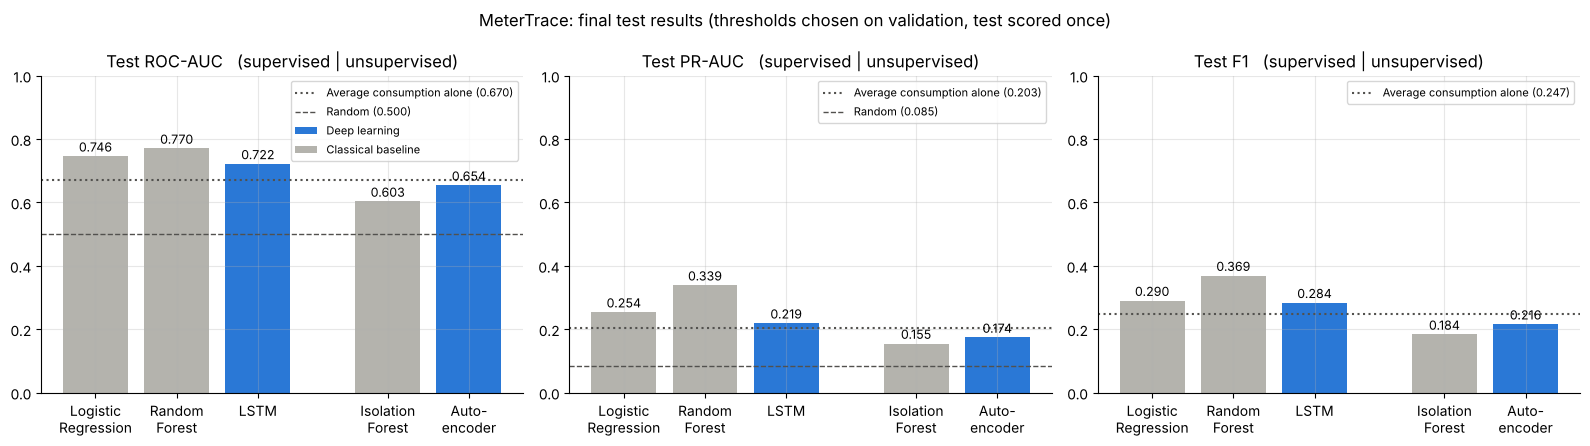

In [15]:
bar_colors = [DEEP_COLOR if model_name in ["LSTM classifier", "Dense autoencoder"] else CLASSICAL_COLOR for model_name in MODEL_NAMES]
bar_positions = np.array([0, 1, 2, 3.6, 4.6])          # gap between supervised and unsupervised
short_names = ["Logistic\nRegression", "Random\nForest", "LSTM", "Isolation\nForest", "Auto-\nencoder"]

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for panel, metric in zip(axes, ["ROC-AUC", "PR-AUC", "F1"]):
    values = test_metrics.loc[MODEL_NAMES, metric].to_numpy()
    panel.bar(bar_positions, values, color=bar_colors, width=0.8)
    for position, value in zip(bar_positions, values):
        panel.text(position, value + 0.015, f"{value:.3f}", ha="center", fontsize=9)
    panel.axhline(test_metrics.loc[REFERENCE_NAME, metric], color=NEUTRAL_COLOR, linestyle=":", linewidth=1.5,
                  label=f"Average consumption alone ({test_metrics.loc[REFERENCE_NAME, metric]:.3f})")
    panel.set_xticks(bar_positions)
    panel.set_xticklabels(short_names)
    panel.set_ylim(0, 1)
    panel.set_title(f"Test {metric}   (supervised | unsupervised)")
    panel.legend(loc="upper right", fontsize=8)
axes[0].axhline(0.5, color=NEUTRAL_COLOR, linestyle="--", linewidth=1, label="Random (0.500)")
axes[1].axhline(y_test.mean(), color=NEUTRAL_COLOR, linestyle="--", linewidth=1, label=f"Random ({y_test.mean():.3f})")
axes[0].bar([0], [0], color=DEEP_COLOR, label="Deep learning")
axes[0].bar([0], [0], color=CLASSICAL_COLOR, label="Classical baseline")
axes[0].legend(loc="upper right", fontsize=8)
axes[1].legend(loc="upper right", fontsize=8)
fig.suptitle("MeterTrace: final test results (thresholds chosen on validation, test scored once)")
plt.tight_layout()
plt.savefig(FIGURE_DIR / "06_test_model_comparison.png", dpi=120)
plt.show()

### 5b. ROC and precision-recall curves
One panel per branch, so each panel compares models of the same kind. The reference (average consumption
alone) is drawn in grey.

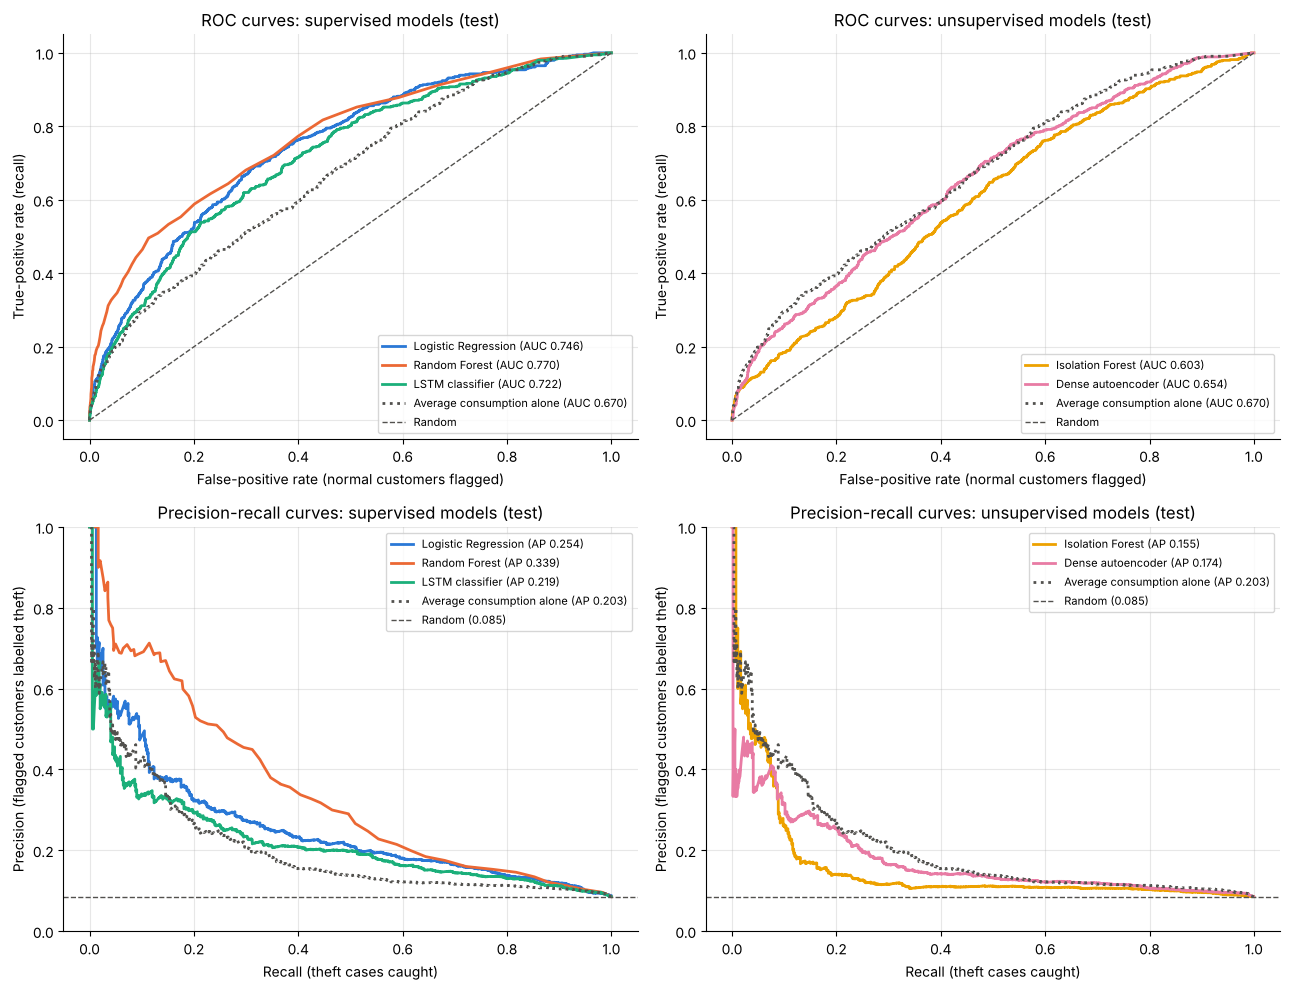

In [16]:
fig, axes = plt.subplots(2, 2, figsize=(13, 10))
for column, (branch_name, branch_models) in enumerate([("Supervised", SUPERVISED), ("Unsupervised", UNSUPERVISED)]):
    roc_panel = axes[0, column]
    pr_panel = axes[1, column]
    for model_name in branch_models + [REFERENCE_NAME]:
        line_style = ":" if model_name == REFERENCE_NAME else "-"
        false_positive_rate, true_positive_rate, _ = roc_curve(y_test, test_scores[model_name])
        roc_panel.plot(false_positive_rate, true_positive_rate, color=MODEL_COLORS[model_name], linestyle=line_style,
                       linewidth=2, label=f"{model_name} (AUC {test_metrics.loc[model_name, 'ROC-AUC']:.3f})")
        precision, recall, _ = precision_recall_curve(y_test, test_scores[model_name])
        pr_panel.plot(recall, precision, color=MODEL_COLORS[model_name], linestyle=line_style,
                      linewidth=2, label=f"{model_name} (AP {test_metrics.loc[model_name, 'PR-AUC']:.3f})")
    roc_panel.plot([0, 1], [0, 1], color=NEUTRAL_COLOR, linestyle="--", linewidth=1, label="Random")
    roc_panel.set_xlabel("False-positive rate (normal customers flagged)")
    roc_panel.set_ylabel("True-positive rate (recall)")
    roc_panel.set_title(f"ROC curves: {branch_name.lower()} models (test)")
    roc_panel.legend(loc="lower right", fontsize=8)
    pr_panel.axhline(y_test.mean(), color=NEUTRAL_COLOR, linestyle="--", linewidth=1, label=f"Random ({y_test.mean():.3f})")
    pr_panel.set_xlabel("Recall (theft cases caught)")
    pr_panel.set_ylabel("Precision (flagged customers labelled theft)")
    pr_panel.set_ylim(0, 1)
    pr_panel.set_title(f"Precision-recall curves: {branch_name.lower()} models (test)")
    pr_panel.legend(loc="upper right", fontsize=8)
plt.tight_layout()
plt.savefig(FIGURE_DIR / "06_test_roc_pr_curves.png", dpi=120)
plt.show()

### 5c. Confusion matrices of the supervised models (test, frozen thresholds)
Rows = true label, columns = model decision. The top-right cell holds the **false alarms** (normal customers
flagged); the bottom-left cell holds the **missed** theft cases.

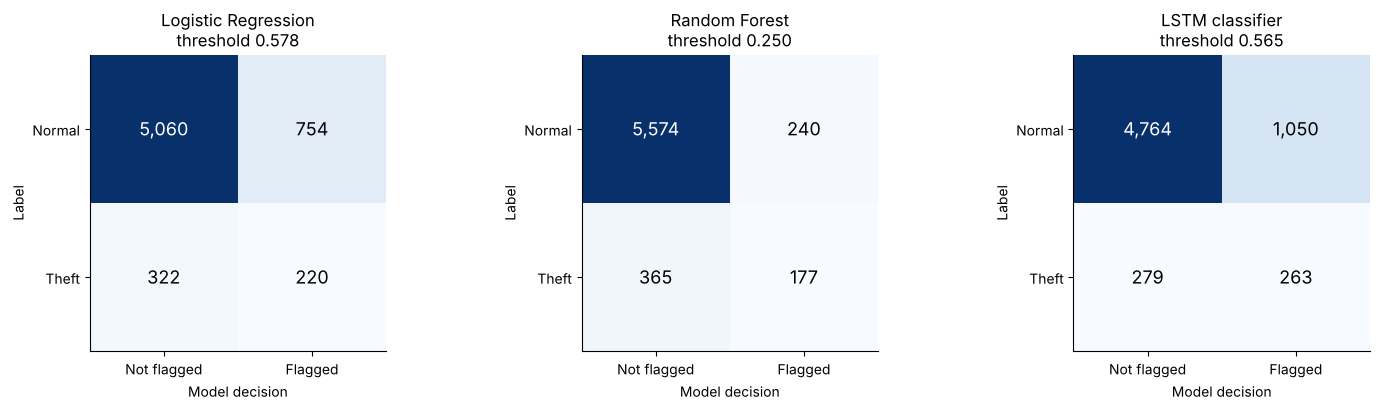

In [17]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
for panel, model_name in zip(axes, SUPERVISED):
    counts = np.array([[test_metrics.loc[model_name, "TN"], test_metrics.loc[model_name, "FP"]],
                       [test_metrics.loc[model_name, "FN"], test_metrics.loc[model_name, "TP"]]])
    panel.imshow(counts, cmap="Blues")
    for row in range(2):
        for column in range(2):
            panel.text(column, row, f"{counts[row, column]:,}", ha="center", va="center", fontsize=13,
                       color="white" if counts[row, column] > counts.max() / 2 else "black")
    panel.set_xticks([0, 1])
    panel.set_xticklabels(["Not flagged", "Flagged"])
    panel.set_yticks([0, 1])
    panel.set_yticklabels(["Normal", "Theft"])
    panel.set_xlabel("Model decision")
    panel.set_ylabel("Label")
    panel.grid(False)
    panel.set_title(f"{model_name}\nthreshold {frozen_thresholds[model_name]:.3f}")
plt.tight_layout()
plt.savefig(FIGURE_DIR / "06_test_confusion_matrices.png", dpi=120)
plt.show()

### 5d. Ranked-customer inspection comparison
Imagine the utility can inspect only a fixed number of customers. Each model ranks the **same** 6,356 test
customers from most to least suspicious. The bars show the share of theft-labelled customers among the
top 100 and top 500, compared with a random choice of customers.

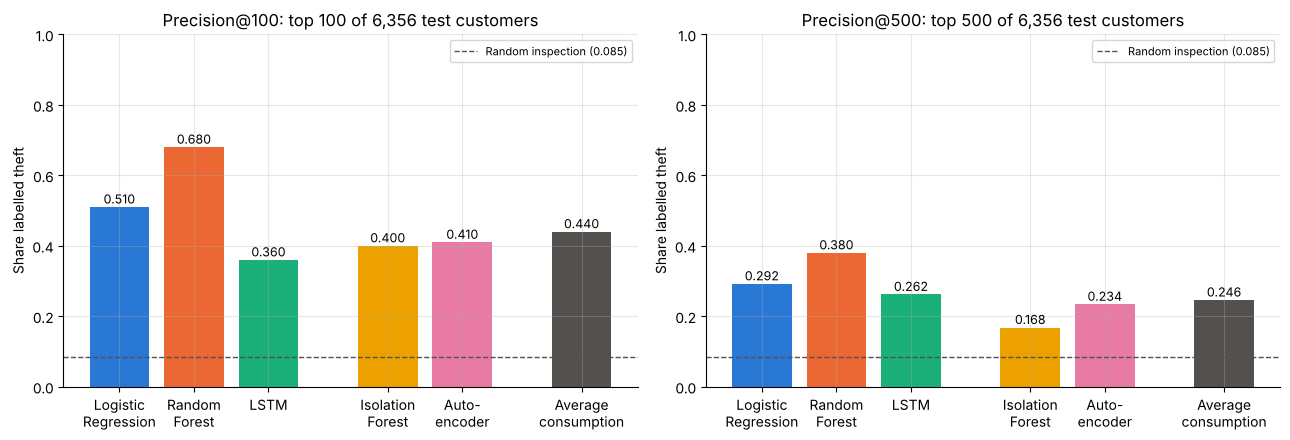

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for panel, k in zip(axes, TOP_K_VALUES):
    names = MODEL_NAMES + [REFERENCE_NAME]
    values = test_metrics.loc[names, f"Precision@{k}"].to_numpy()
    positions = np.array([0, 1, 2, 3.6, 4.6, 6.2])
    panel.bar(positions, values, color=[MODEL_COLORS[name] for name in names], width=0.8)
    for position, value in zip(positions, values):
        panel.text(position, value + 0.01, f"{value:.3f}", ha="center", fontsize=9)
    panel.axhline(y_test.mean(), color=NEUTRAL_COLOR, linestyle="--", linewidth=1,
                  label=f"Random inspection ({y_test.mean():.3f})")
    panel.set_xticks(positions)
    panel.set_xticklabels(short_names + ["Average\nconsumption"])
    panel.set_ylim(0, 1)
    panel.set_ylabel("Share labelled theft")
    panel.set_title(f"Precision@{k}: top {k} of {len(y_test):,} test customers")
    panel.legend(loc="upper right", fontsize=8)
plt.tight_layout()
plt.savefig(FIGURE_DIR / "06_test_precision_at_k.png", dpi=120)
plt.show()

**Reading the figures.**
- **ROC curves (supervised):** Random Forest's curve lies above the others at the left end. That is the
  region that matters for inspections, where only a few customers are flagged.
- **Precision-recall curves:** the Random Forest curve stays clearly higher at low recall, which is why its
  Precision@100 is the best. All curves fall towards the random line (0.085) as recall approaches 1. To
  catch nearly all theft cases, a utility would have to inspect almost everyone.
- **Unsupervised curves:** the grey dotted reference (average consumption) lies on or above both
  unsupervised curves for most of the range.
- **Confusion matrices:** the cost of each threshold is visible.
  - The LSTM catches 263 of 542 theft cases but raises 1,050 false alarms.
  - Random Forest catches 177 with only 240 false alarms.
  - Logistic Regression lies in between (220 caught, 754 false alarms).
- **Inspection comparison:** if inspectors visit the 100 customers Random Forest ranks highest, 68 are
  labelled theft. A random choice of 100 customers would contain about 8 or 9.

## 6. Save customer-level test scores
One row per test customer, in the saved test order, with each model's score and decision. Notebooks 07 and 08
use this file. They may *explain* and *display* these results, but must not change models or thresholds.

In [19]:
customer_level = test_scores.copy()
for model_name in ALL_NAMES:
    customer_level[f"{model_name} flagged"] = test_scores[model_name].to_numpy() >= frozen_thresholds[model_name]
customer_level["in_contradictory_group"] = customers.loc[test_scores.index, "in_contradictory_group"].to_numpy()
customer_level.index.name = "CONS_NO"
customer_level.to_csv(RESULTS_DIR / "06_test_scores.csv")

reloaded = pd.read_csv(RESULTS_DIR / "06_test_scores.csv", index_col="CONS_NO")
print("Saved outputs/results/06_test_scores.csv:", reloaded.shape)
print("Row order identical to the test feature file:", bool((reloaded.index == test_features.index).all()))
print("No missing values:", int(reloaded.isna().sum().sum()) == 0)

Saved outputs/results/06_test_scores.csv: (6356, 14)
Row order identical to the test feature file: True
No missing values: True


## Conclusions

**Best model: Random Forest on the 11 engineered features.**
- **Scores:** test ROC-AUC 0.7702, PR-AUC 0.3389, Precision@100 0.68, Precision@500 0.380.
- **Why it wins:**
  - It combines the daily-level features from Notebook 03 (consumption level and spread, change over time,
    spikes, missingness) **non-linearly**.
  - Logistic Regression can only add them up linearly.
  - The LSTM and autoencoder only see smoothed, partly imputed **weekly** averages.

**Deep learning, reported honestly:**
- **LSTM:** it learned something useful (ROC-AUC 0.7216, above the reference) but did **not** beat the
  hand-made features.
- **Autoencoder:** it **did** beat Isolation Forest, so a learned picture of normal usage is better than
  the classical anomaly detector. However, neither unsupervised model beat ranking customers by average
  consumption.

**Class imbalance and the catch-vs-false-alarm trade-off:**
- Only 8.53% of test customers are labelled theft, so "everyone is normal" scores 91.47% accuracy while
  catching nothing.
- With these models, every extra theft case caught costs extra false alarms. For example, the LSTM's
  threshold catches 86 more theft cases than Random Forest's but flags 810 more normal customers.
- How many false alarms are acceptable depends on the utility's inspection budget. That is why
  Precision@k matters.

**Limitations:**
- **Customer-level labels only:** labels are per customer, with no date, and the labelling process is
  undocumented.
- **Contradictory labels:** 91 test customers belong to identical-history groups with contradictory labels
  (all zero-consumption meters), and no model can be right about all of them.
- **One dataset:** the data comes from one utility and one region.
- **Not causal:** we found *associations*, for example that theft-labelled customers consume more, not
  causes.

**Investigation leads, not proof:** a high score means the account deserves a closer look. Even among
Random Forest's top 100 test customers, 32 are labelled normal. Every flag must be checked by a human
inspector.

## What We Learned
Key ideas to be able to explain in the viva:

1. **Freeze decisions before testing.** Thresholds were chosen with one rule (maximum validation F1),
   written to a file, and only then was the test set scored once. Nothing was changed afterwards.
2. **One rule, different thresholds.** Each model's score has its own scale (probability, anomaly score,
   reconstruction error, kWh), so the same F1 rule gives very different thresholds and flagging rates.
3. **Ranking metrics vs. threshold metrics.** ROC-AUC, PR-AUC and Precision@k judge the *ranking*.
   Precision, recall, F1 and the false-positive rate judge one *chosen threshold*. A model can rank well
   but sit at an unhelpful threshold, or the other way round.
4. **Precision@k answers the practical question:** "If we can inspect only k customers, how many will be
   labelled theft?" Random Forest: 68 of the top 100.
5. **The catch-vs-false-alarm trade-off is unavoidable.** Lowering a threshold raises recall and the
   false-positive rate together, as both the confusion matrices and the validation trade-off table show.
6. **Compare against simple references.** "Average consumption alone" was a demanding baseline. It beat
   both unsupervised models and matched the LSTM on Precision@100.
7. **Validation and test agree.** Similar scores on both sets show the results are stable, not lucky.
8. **Scores are leads, not verdicts.** Labels are imperfect and customer-level, and unusual consumption
   can have innocent causes, so every flagged customer needs human review.